## Notebook to explore for the 2026 project


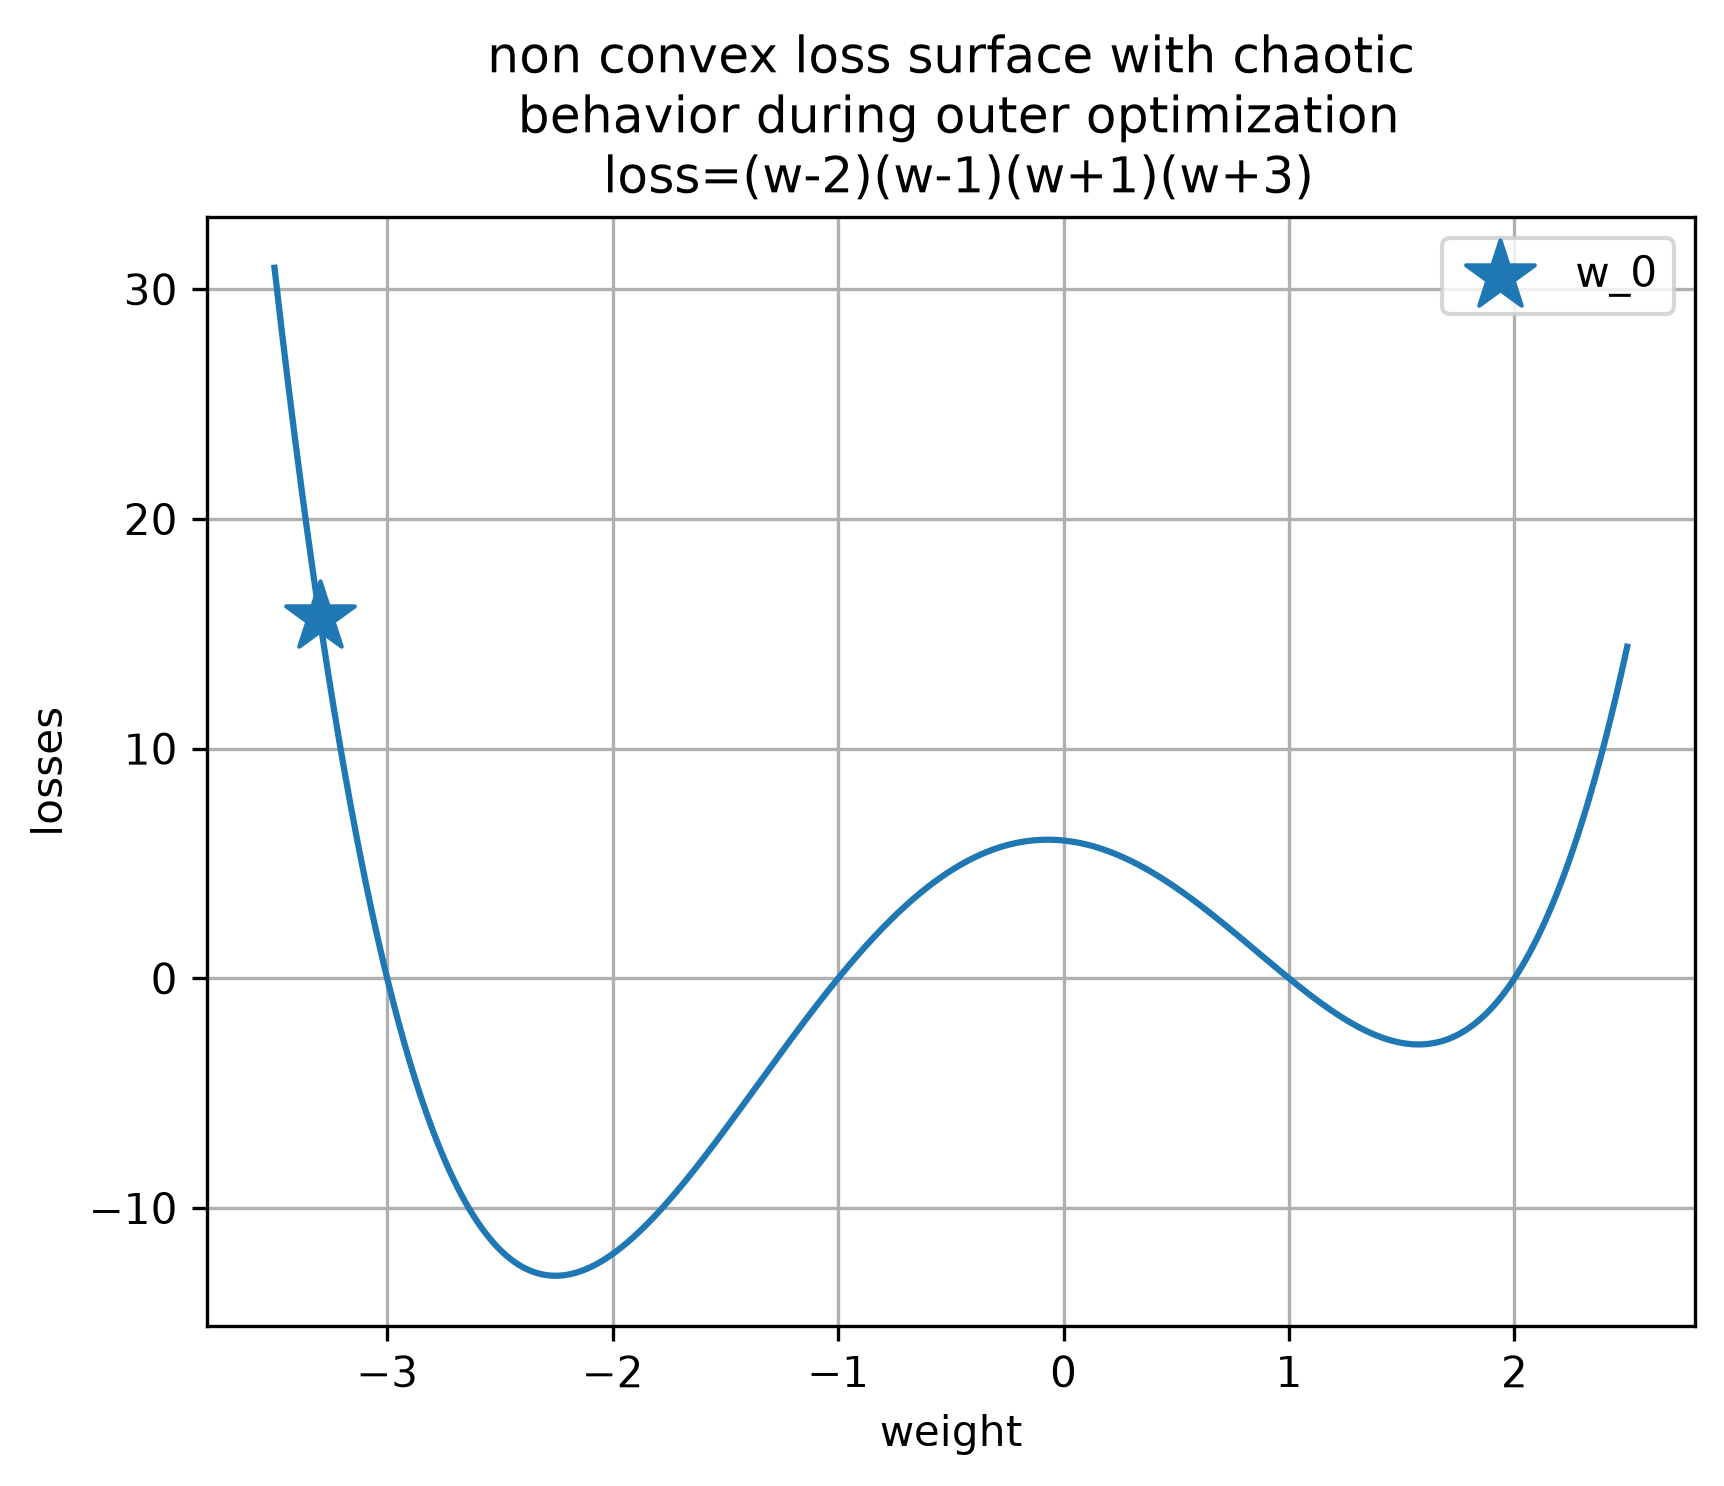

In [215]:
import matplotlib.pyplot as plt
import numpy as np
# example of non convex loss surface with poor/chaotic behavior during outer optimization
def loss_fn(w):
    return (w - 2) * (w - 1) * (w + 1) * (w + 3)
ws = np.linspace(-3.5,2.5, 1000)
w_0 = -3.3
losses = loss_fn(ws)
plt.figure(dpi=300)
plt.title("non convex loss surface with chaotic\n behavior during outer optimization\n loss=(w-2)(w-1)(w+1)(w+3)")
plt.plot(ws, losses)
plt.ylabel("losses")
plt.xlabel("weight")
plt.grid()
plt.scatter([w_0],[loss_fn(w_0)], label="w_0", marker="*", s=300)
plt.legend()
plt.show()

In [216]:
from collections import deque, defaultdict
class Parameter:
    def __init__(self, data, _op=None):
        self.data = data
        self.grad = 0
        self._op = _op
        # self.retain_grads = retain_grads
        
        self._parents = []

    def backwards(self, dout=None):
        # where you call .backwards for the first time is unique right? 
        # then everywhere else calls backwards with the inputs from the prior function
        if dout is None:
            # all nodes have a parent relation. is there some way to get their 
            # the nodes which don't have a parent relation are definitely my source, 
            # then from there, if I consider removing those nodes and check for the nodes which have no parents after this,
            # I will find the next nodes in the topological ordering
            root = self
            dependency_count = defaultdict(int)
            dependency_count[root] = 0
            queue = deque()
            queue.append(root)
            while len(queue) != 0:
                node = queue.popleft()
                node.grad = 0 if node.grad is None else node.grad
                for nnode in node._parents:
                    dependency_count[nnode] += 1
                    queue.append(nnode)
            # print(set(dependency_count.keys()))
            # print(dependency_count)
            assert dependency_count[root] == 0
            # now go through the graph again, but only add nodes when they are out of dependencies.
            queue.append(root)
            root.grad = 1
            while len(queue) != 0:
                node = queue.popleft()
                node.backwards(1)
                for nnode in node._parents:
                    dependency_count[nnode] -= 1
                    if dependency_count[nnode] == 0:
                        queue.append(nnode)
        else:
            if self._op:
                self._op()

        # it is very possible to not have something to do with your grad, and no one to pass anything to. 
        # This happens at leaf nodes.

    def __neg__(self):
        def neg_backward():
            self.grad += -new_p.grad
        new_p = Parameter(-self.data, neg_backward)
        new_p._parents = [self]
        return new_p
    def __add__(self, other):
        if not isinstance(other, Parameter):
            other = Parameter(other)
        def add_backward():
            self.grad += new_p.grad
            other.grad += new_p.grad
        new_p = Parameter(self.data + other.data, add_backward)
        new_p._parents = [self, other]
        return new_p
    def __mul__(self, other):
        if not isinstance(other, Parameter):
            other = Parameter(other)
        def mul_backward():
            self.grad += new_p.grad * other.data
            other.grad += new_p.grad * self.data
        new_p = Parameter(self.data * other.data, mul_backward)
        new_p._parents = [self, other]
        return new_p
    def __sub__(self, other):
        return self.__add__(-other)
    def __repr__(self):
        return f"Parameter({self.data}, backwards_fn={self._op})"

# w = Parameter(10)
# loss = -w
# loss.backwards()
# w.grad

# a = Parameter(3)
# b = Parameter(4)
# x_1 = a * a
# x_2 = a * b
# x_3 = -x_2
# x_4 = x_1 + x_2
# x_5 = x_3 + x_4
# x_5.backwards()

# a.grad, b.grad, x_1.grad, x_2.grad, x_3.grad, x_4.grad, x_5.grad

In [402]:
# making the second figure, I guess this is going to be a bit of 
# opacity to try to see the effect of momentum on the dynamics of the optization?
# well, to make one training run, I have to construct the SGD solution to this, 
# which is to create an optimizer for the single parameter setting.
from collections import defaultdict
class SGD_custom:
    def __init__(self, parameters, lr, momentum):
        self.param_groups = [{"params": parameters, "lr": lr, "momentum": momentum}]
        # the state is a default dict which maps from individual parameters to their corresponding state.
        self.state: dict[Parameter, dict] = defaultdict(dict)
        # for pg in self.param_groups:
        #     for param in pg['params']:
        #         ...
        # I have to have some storage of the gradient's momentum?
    def step(self, ):
        for pg in self.param_groups:
            lr = pg['lr']
            momentum = pg['momentum']
            for param in pg['params']:
                step = self.state[param].get("step", 1)
                grad = param.grad # will have populated this with .backwards(), and now need to store the momentum term of the gradient somewhere?
                grad_first_moment = self.state[param].get('grad_first_moment', 0) # this only works because the parameter is always a single value in my case.
                new_grad_first_moment = momentum * grad_first_moment + (1-momentum) * grad
                # debiasing is removing the effect of the first zero, which has weight momentum ** step
                param.data -= lr*new_grad_first_moment/(1 - momentum**step)
                self.state[param]['step'] = step + 1
                self.state[param]['grad_first_moment'] = new_grad_first_moment
    def zero_grad(self, ):
        for pg in self.param_groups:
            for param in pg['params']:
                param.grad = None

# control the lower and upper bound, and take log space steps between them.
lr_min = 0.005
lr_max = 0.07
r = lr_max - lr_min
# 0,...,1 to transform this to the range lr_min, ..., lr_max? but how do I get this in log space?
# perhaps I just do e ** i, renormalize, and then do it
num_lrs = 100
# lr_min * rate ** steps = lr_max
# we want to know the rate we should step, essentially?
# log_{2}lr_max 
lr_step_rate = (lr_max/lr_min)**(1/num_lrs)
lrs = [lr_min * lr_step_rate**(i+1) for i in range(num_lrs)]
momentum_min = 0.9
momentum_max = 0.999
num_momentums = 1000
momentum_step_rate = (momentum_max/momentum_min)**(1/num_momentums)

momentums = [momentum_min * momentum_step_rate**(i+1) for i in range(num_momentums)]
all_ws = []
steps = 501
lr = 0.07
# lr schedule
# slope intercept
# y = mx + b
# define a line by two points. 
# Goes through x_1, y_1, and x_2, y_2
# define the slope, define the intercept?
# slope is (y_2 - y_1)/(x_2-x_1), intercept is? -x_2 * slope
lr_schedule = lambda i: min((i/10), 1) # (steps-10) * -1/(10-steps))
momentum = 0.9
# for lr in lrs:
for momentum in momentums:
    w = Parameter(w_0)
    optim = SGD_custom([w], lr, momentum)
    ws = []
    for i in range(steps):
        optim.zero_grad()
        loss = loss_fn(w)
        loss.backwards()
        for pg in optim.param_groups:
            pg['lr'] = lr_schedule(i) * lr
        optim.step()
        ws.append(w.data)
    all_ws.append(ws)

In [291]:
steps

501

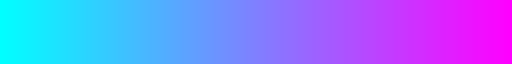

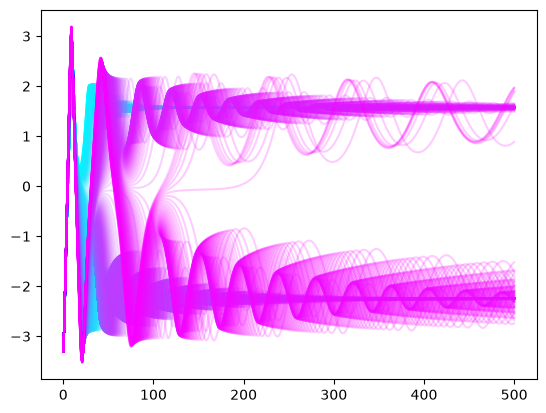

In [403]:
from matplotlib import colormaps
from matplotlib.colors import Normalize
cmap = colormaps.get_cmap("cool")

for i, ws in enumerate(all_ws):
    index = int(i / len(all_ws) * 255)
    plt.plot(ws, color=cmap(index), alpha=0.2)
cmap



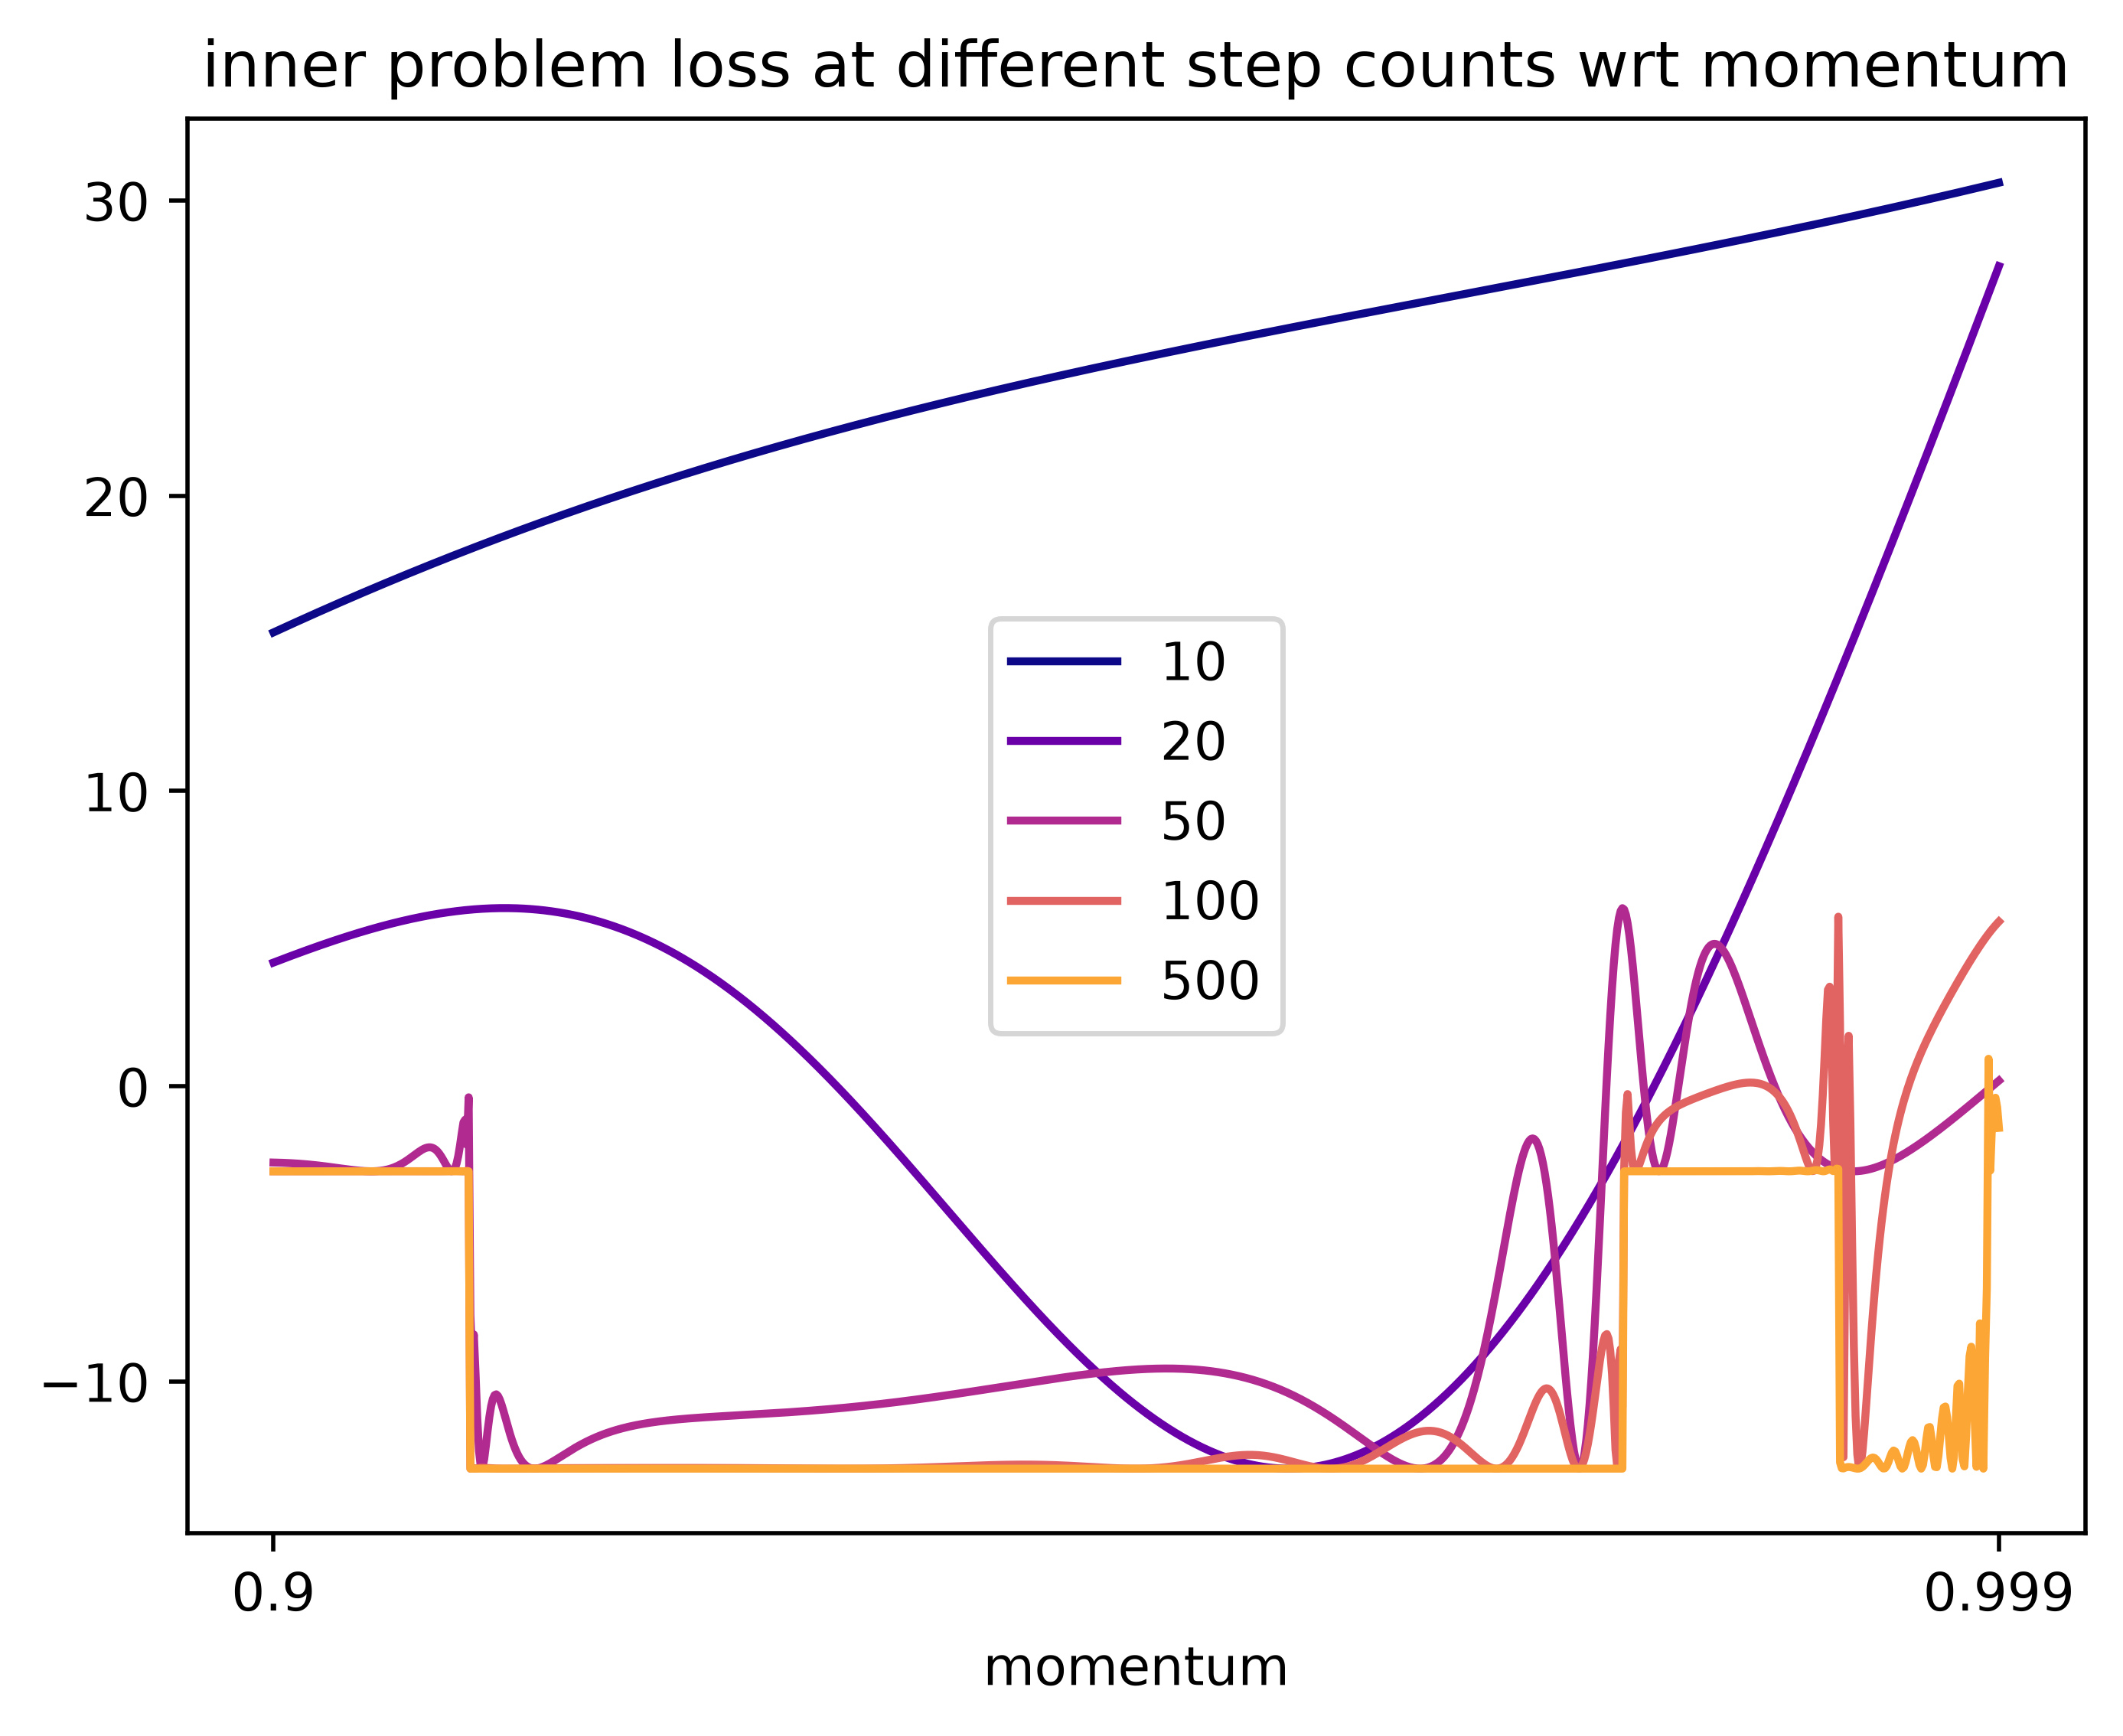

In [404]:
# plotting the final loss as a function of the number of steps
steps = [10,20,50,100,500]
cmap = colormaps.get_cmap("plasma")
plt.figure(dpi=500)
for i, step in enumerate(steps):
    losses_at_step = [loss_fn(ws[step]) for ws in all_ws]
    color = cmap(int(i / len(steps) * 255))
    plt.plot(losses_at_step, color=color, label=f"{step}")
plt.xticks([0,len(losses_at_step)-1],[momentum_min, momentum_max])
plt.xlabel("momentum")
plt.legend()
plt.title("inner problem loss at different step counts wrt momentum")
plt.show()

In [ ]:
# asking question of how does loss appear to change for small step

1

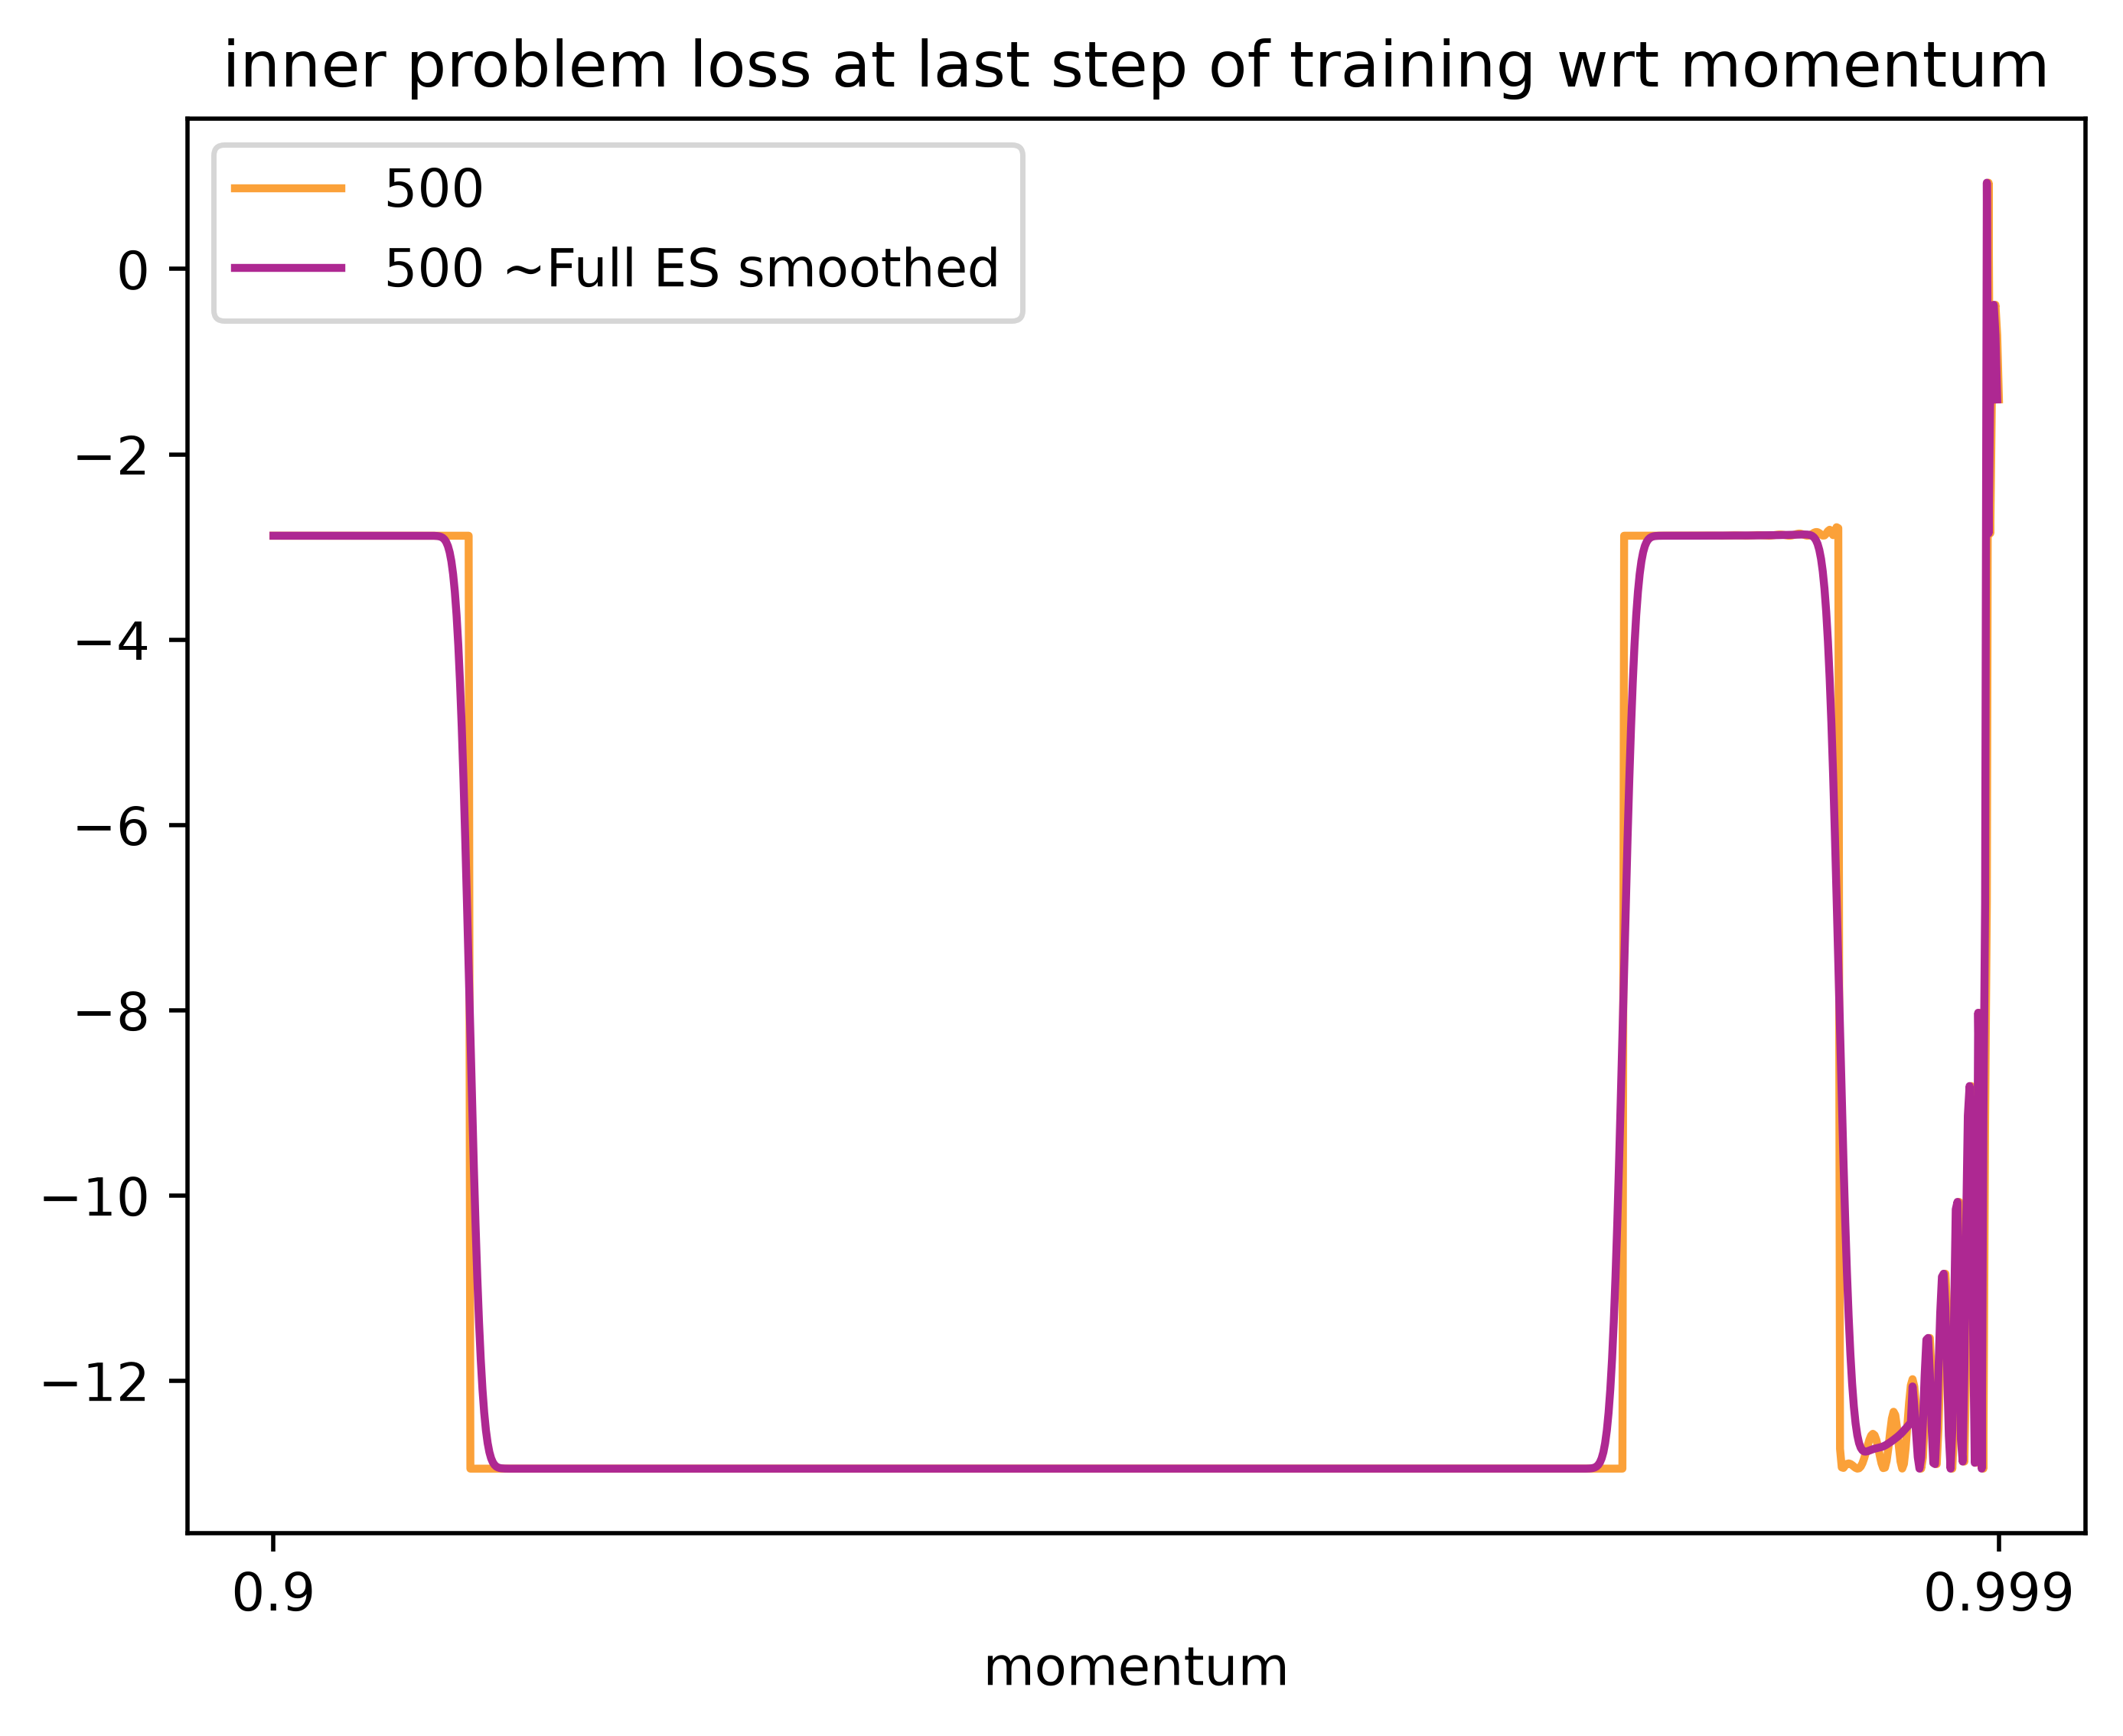

In [405]:
# their method essentially will smooth the loss landscape directly, 
# but this prevents the use of any first order information.

# Can I plot the smoothed loss landscape directly?
cmap = colormaps.get_cmap("plasma")
plt.figure(dpi=500)
losses_at_step = [loss_fn(ws[-1]) for ws in all_ws]
sigma = 30
k = 50
gaussian_kernel = [(1/((2 * 3.1415)**0.5 * sigma) *2.72**(-(i-k)**2/(2*sigma))) for i in range(0,2*k+1)] # smooth 10 values in log space? ahh whatever, should be ok ish
gaussian_kernel = [g / sum(gaussian_kernel) for g in gaussian_kernel]
losses_at_step_smoothed = [sum(g*l for g,l in zip(gaussian_kernel,losses_at_step[i:i+2*k+1])) for i in range(len(losses_at_step) - 2*k-1)]
plt.plot(losses_at_step, color=cmap(200), label=f"{step}")
plt.plot(losses_at_step[:k]+ losses_at_step_smoothed + losses_at_step[-k:], color=cmap(100), label=f"{step} ~Full ES smoothed")
plt.xticks([0,len(losses_at_step)-1],[momentum_min, momentum_max])
plt.xlabel("momentum")
plt.legend()
plt.title("inner problem loss at last step of training wrt momentum")
plt.show()


In [ ]:
# simulate the landscape which could appear from my proposed solution? 
# this would involve truncations, because the truncations would tell me where to move, 
# not just the full ES,
import random
momentum_min = 0.9
momentum_max = 0.999
num_momentums = 1000
momentum_step_rate = (momentum_max/momentum_min)**(1/num_momentums)

momentums = [momentum_min * momentum_step_rate**(i+1) for i in range(num_momentums)]
all_ws_new = []
steps = 501
lr = 0.07
lr_schedule = lambda i: min((i/10), 1) # (steps-10) * -1/(10-steps))
# momentum = 0.9
num_samples = 50

# for lr in lrs:
for momentum in momentums:

    ws = []
    for sample in range(num_samples):
        w = Parameter(w_0)
        optim = SGD_custom([w], lr, momentum)
        sample_ws = []
        for i in range(steps):
            optim.zero_grad()
            loss = loss_fn(w)
            loss.backwards()
            for pg in optim.param_groups:
                pg['lr'] = lr_schedule(i) * lr
            optim.step()
            # NEW: add noise to the weight directly, not the momentum
            sample_ws.append(w.data)
            w.data += (2*random.random()-1)*0.01
        ws.append(sample_ws)
    all_ws_new.append(ws)

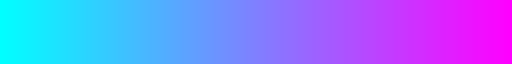

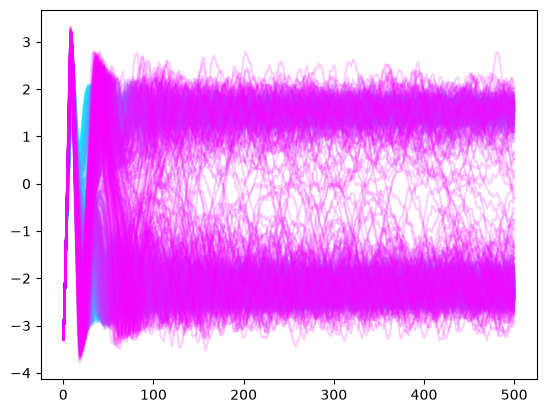

In [ ]:
cmap = colormaps.get_cmap("cool")
for i, wss in enumerate(all_ws_new):
    index = int(i / len(all_ws) * 255)
    # for ws in wss:
    plt.plot(wss[2], color=cmap(index), alpha=0.2)
cmap

In [408]:
# all_ws_new = 
[[sum(loss_fn(w) for w in w_ts)/len(w_ts) for w_ts in zip(*wss)] for wss in all_ws_new];


In [420]:
# PES
import random
momentum_min = 0.9
momentum_max = 0.999
num_momentums = 1000
momentum_step_rate = (momentum_max/momentum_min)**(1/num_momentums)

momentums = [momentum_min * momentum_step_rate**(i+1) for i in range(num_momentums)]
all_ws_pes = []
steps = 501
lr = 0.07
lr_schedule = lambda i: min((i/10), 1) # (steps-10) * -1/(10-steps))
# momentum = 0.9
num_samples = 10

# for lr in lrs:
for momentum in momentums:

    ws = []
    for sample in range(num_samples):
        w = Parameter(w_0)
        optim = SGD_custom([w], lr, momentum)
        sample_ws = []
        for i in range(steps):
            optim.zero_grad()
            loss = loss_fn(w)
            loss.backwards()
            for pg in optim.param_groups:
                pg['momentum'] = momentum + (2*random.random()-1)*0.001
                pg['lr'] = lr_schedule(i) * lr
            optim.step()
            sample_ws.append(w.data)
        ws.append(sample_ws)
    all_ws_pes.append(ws)
all_ws_pes = [[sum(loss_fn(w) for w in w_ts)/len(w_ts) for w_ts in zip(*wss)] for wss in all_ws_pes];

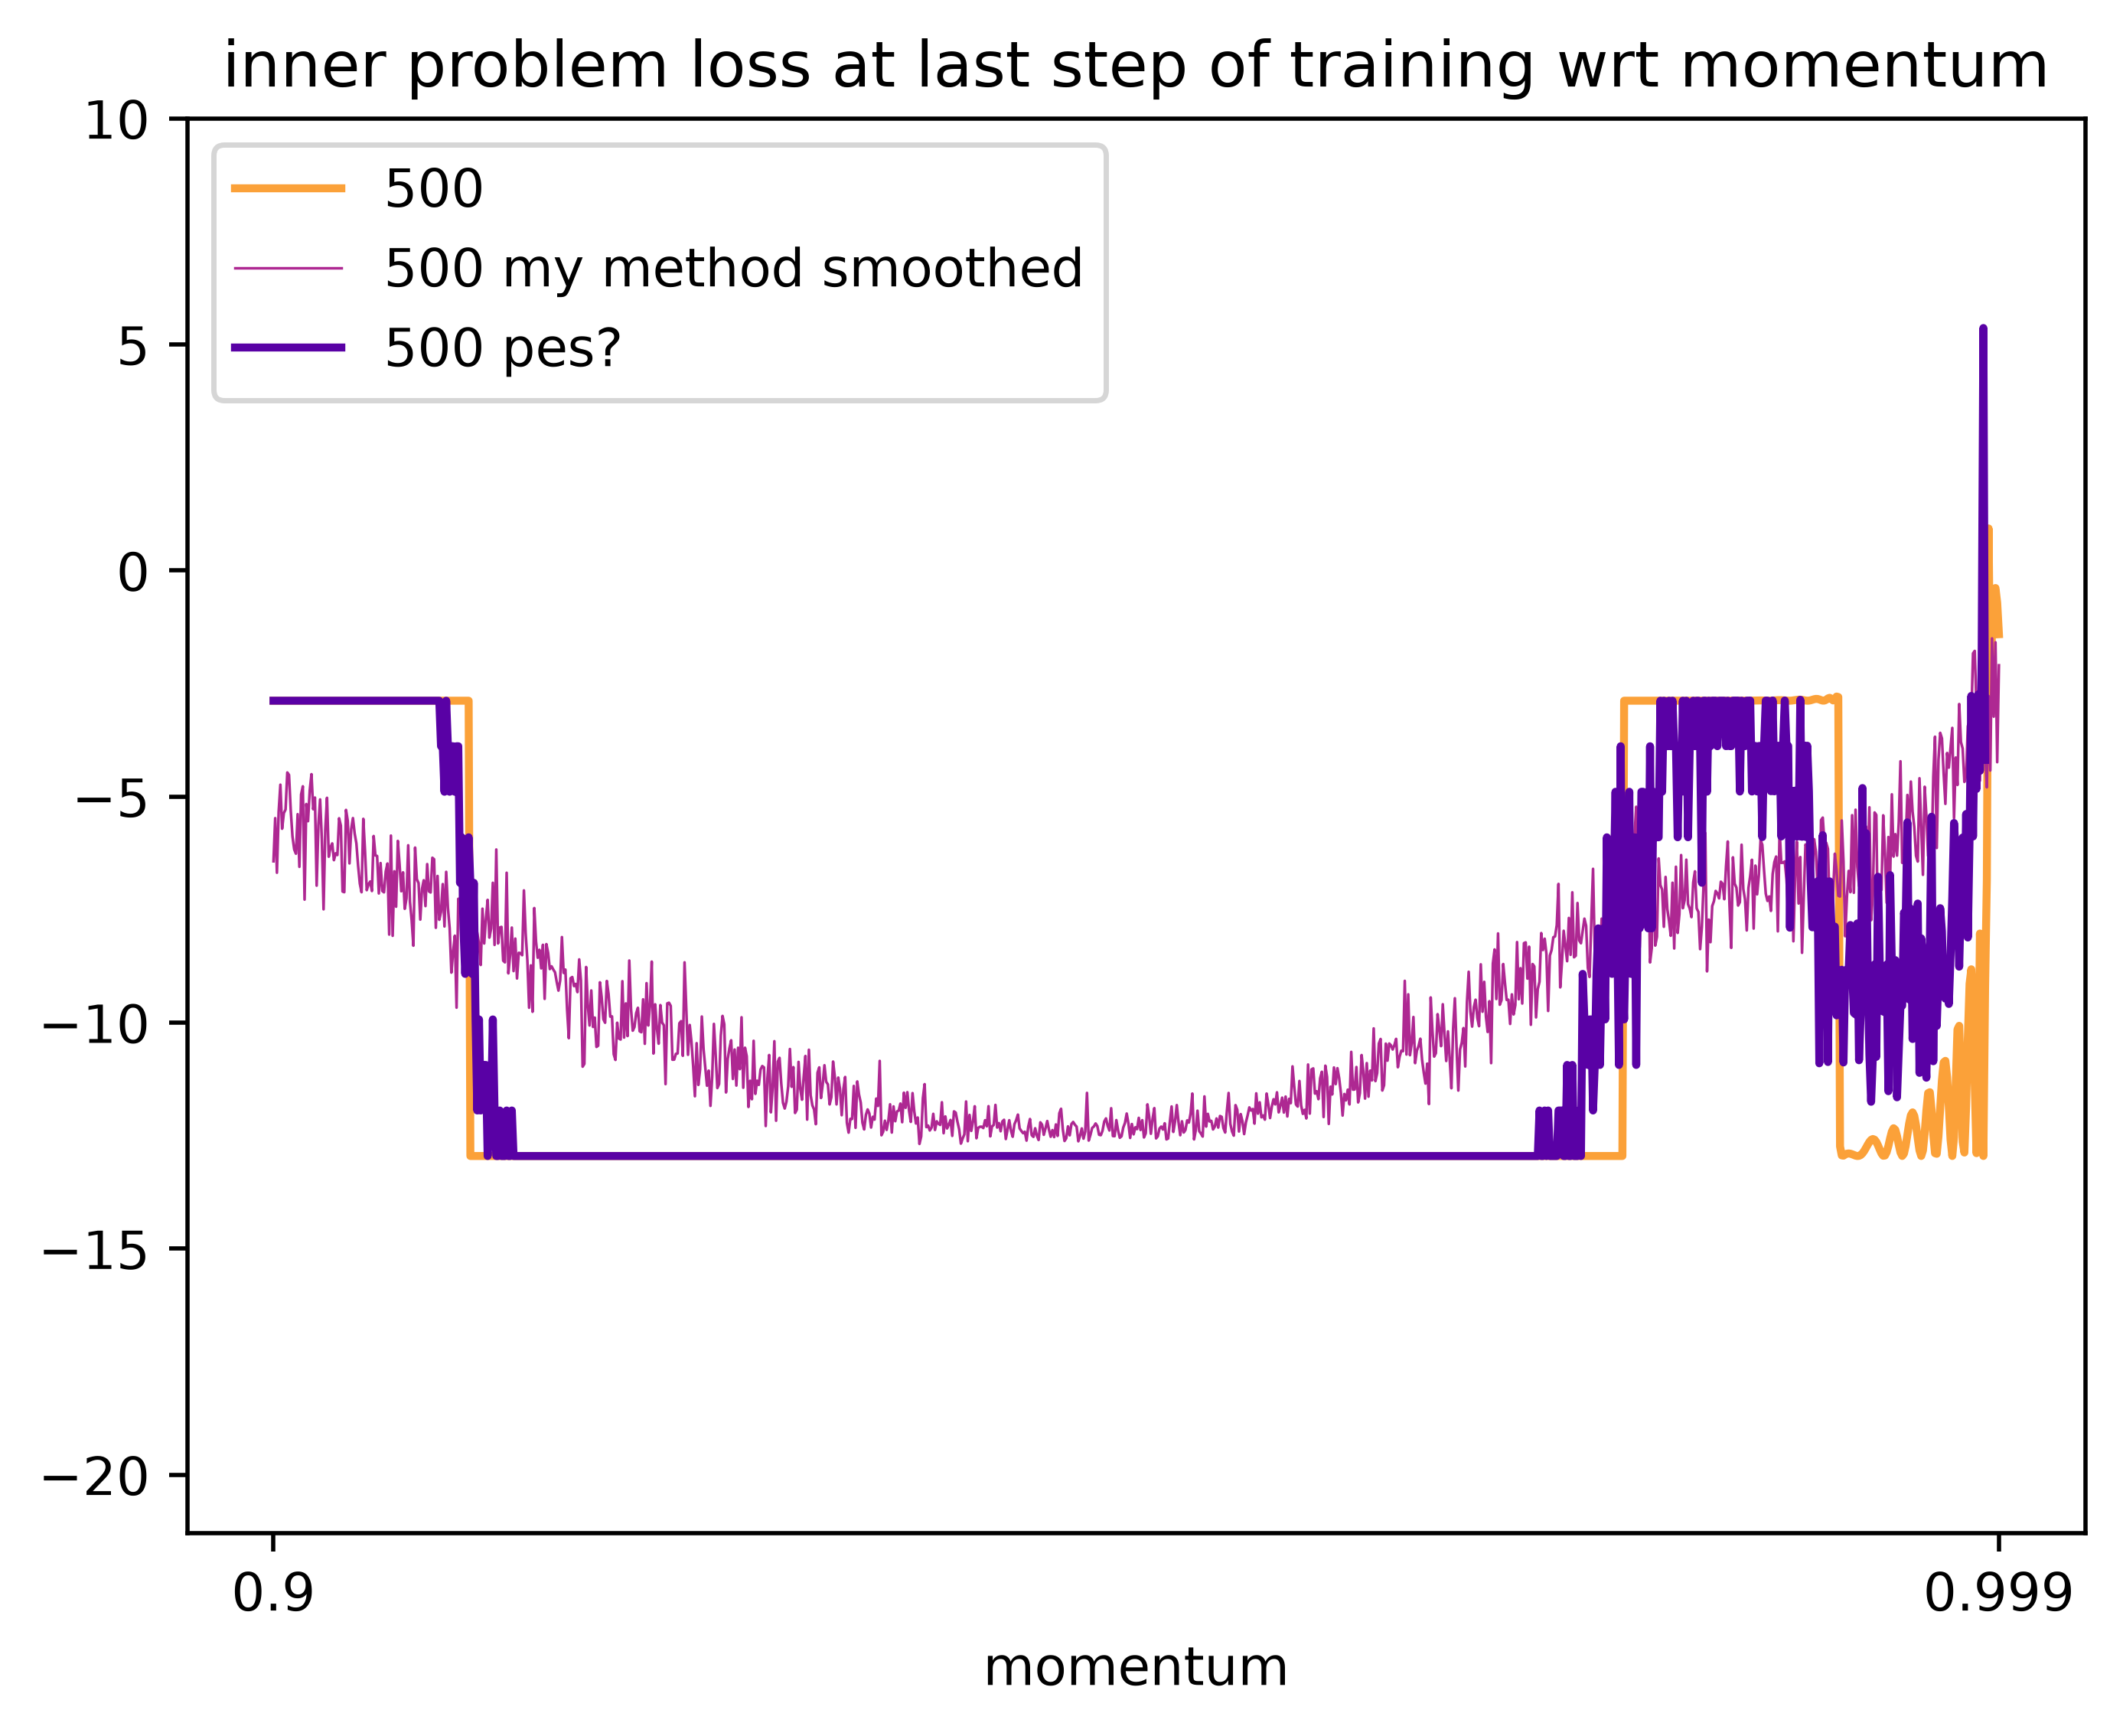

In [ ]:
cmap = colormaps.get_cmap("plasma")
plt.figure(dpi=500)
losses_at_step = [loss_fn(ws[-1]) for ws in all_ws]
losses_at_step_new = [ws[-1] for ws in [[sum(loss_fn(w) for w in w_ts)/len(w_ts) for w_ts in zip(*wss)] for wss in all_ws_new]]
losses_at_step_pes = [ws[-1] for ws in all_ws_pes]
plt.plot(losses_at_step, color=cmap(200), label=f"{step}")
# plt.plot(losses_at_step[:k]+ losses_at_step_smoothed + losses_at_step[-k:], color=cmap(100), label=f"{step} ~Full ES smoothed")
plt.plot(losses_at_step_new, color=cmap(100), label=f"{step} my method smoothed", linewidth=0.5)
plt.plot(losses_at_step_pes, color=cmap(40), label=f"{step} pes?")
plt.xticks([0,len(losses_at_step)-1],[momentum_min, momentum_max])
plt.xlabel("momentum")
plt.legend()
plt.title("inner problem loss at last step of training wrt momentum")
plt.ylim(ymax=10)
plt.show()